# Домашнее задание 3. Градиентный спуск, Ньютон, BFGS: реализация и сравнение

**Выдано:** 7 октября 2026. **Срок сдачи:** 21 октября 2026 (до начала занятия). **Максимум:** 10 баллов (+1 бонус).

**Как сдавать.** Работа сдаётся в ваш личный закрытый репозиторий `optimisation-misis-2026/numopt-<ваш логин>`: его видите только вы и преподаватель, приглашение приходит на почту, привязанную к GitHub. Этот ноутбук уже лежит там как `hw3/homework.ipynb`. Заполните его (ответы на теоретические вопросы — в markdown-ячейках, формулы в $\LaTeX$; код — в code-ячейках), выполните целиком (`Kernel → Restart Kernel and Run All Cells`) и загрузите обратно в папку `hw3/` под тем же именем (на github.com: *Add file → Upload files*); пошагово — в [инструкции](https://github.com/IlyaChichkanov/Numerical-Optimization/blob/main/CONTRIBUTING.md). Если вы уже сдали ДЗ 3 pull request'ом, ничего делать не нужно — работа засчитана. Задачи можно обсуждать, но текст и код пишутся самостоятельно; своё решение никому не показывайте.

**Материал:** лекция 4 ([конспект](https://github.com/IlyaChichkanov/Numerical-Optimization/blob/main/lectures/lecture04/lecture04.md)) и лекция 5 ([конспект](https://github.com/IlyaChichkanov/Numerical-Optimization/blob/main/lectures/lecture05/lecture05.md), [демо](https://github.com/IlyaChichkanov/Numerical-Optimization/blob/main/lectures/lecture05/demo05.ipynb), [семинар](https://github.com/IlyaChichkanov/Numerical-Optimization/blob/main/lectures/lecture05/seminar05.ipynb)). Ничего сверх лекций не требуется. Ориентировочное время — 3–4 часа.

**Устройство задания.** Обвязка — функции Розенброка, цепь, данные синуса, рисовальщики — дана готовой в ячейке ниже; вы пишете только то, что составляет метод: направление, выбор длины шага, обновление матрицы, шаг Гаусса–Ньютона. Под каждым заданием стоит проверка (`assert`), которая ловит смысл: если она прошла, можно идти дальше. Все методы работают с одними и теми же параметрами, чтобы числа совпали с конспектом: backtracking по Армихо с $c=10^{-4}$ от $\alpha=1$ делением пополам, останов по $\lVert\nabla f\rVert\le10^{-6}$ (у Ньютона — $10^{-10}$).

Запуск: `uv sync` в корне репозитория, затем `uv run jupyter lab`; в Colab ничего ставить не нужно.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize, least_squares

rng = np.random.default_rng(2026)   # не меняйте seed: данные должны совпадать у всех

BLUE, ORANGE, AQUA, RED, VIOLET, GRAY, INK = "#2a78d6", "#eb6834", "#1baf7a", "#e34948", "#4a3aa7", "#8a8985", "#0b0b0b"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.2, "legend.frameon": False})


# ---------------------------------------------------------------- задачи (даны готовыми)
def rosen(x):
    return (1 - x[0]) ** 2 + 100 * (x[1] - x[0] ** 2) ** 2


def rosen_grad(x):
    return np.array([-2 * (1 - x[0]) - 400 * x[0] * (x[1] - x[0] ** 2), 200 * (x[1] - x[0] ** 2)])


def rosen_hess(x):
    return np.array([[2 - 400 * x[1] + 1200 * x[0] ** 2, -400 * x[0]], [-400 * x[0], 200.0]])


X0_ROSEN = np.array([-1.2, 1.0])


def make_chain(N, D=70.0, g=9.81):
    """Цепь без пола (лекция 1, §7.3; лекция 4): E(v) = 1/2 v^T H v + b^T v + const.
    Возвращает (energy, grad_E, H, b, v0): функция, градиент, гессиан, линейный член, старт (прямая между концами)."""
    m = 4.0 / N
    K = 2 * np.eye(N) - np.eye(N, k=1) - np.eye(N, k=-1)
    H = np.kron(np.eye(2), D * K)
    b = np.zeros(2 * N)
    b[0] -= D * (-2.0); b[N - 1] -= D * 2.0; b[N] -= D * 1.0; b[2 * N - 1] -= D * 1.0; b[N:] += m * g
    v0 = np.r_[np.linspace(-2, 2, N + 2)[1:-1], np.ones(N)]

    def energy(v):
        y, z = np.r_[-2.0, v[:N], 2.0], np.r_[1.0, v[N:], 1.0]
        return 0.5 * D * np.sum(np.diff(y) ** 2 + np.diff(z) ** 2) + m * g * np.sum(z[1:-1])

    return energy, (lambda v: H @ v + b), H, b, v0


# данные задачи 2(б) ДЗ 2: y = 2 sin(3t + 0.7) + шум, 60 точек, те же 20 стартов
data_rng = np.random.default_rng(2026)
t_data = np.sort(data_rng.uniform(0, 2 * np.pi, 60))
y_data = 2.0 * np.sin(3.0 * t_data + 0.7) + 0.2 * data_rng.standard_normal(60)
starts = data_rng.uniform(-5, 5, (20, 3))
X0_SINE = np.array([1.0, 3.0, 0.0])


def sine_resid(x):
    """Невязки модели x1 sin(x2 t + x3) на данных."""
    return x[0] * np.sin(x[1] * t_data + x[2]) - y_data


def sine_jac(x):
    """Якобиан невязок (60 x 3): столбцы — производные по амплитуде, частоте, фазе."""
    s, c = np.sin(x[1] * t_data + x[2]), np.cos(x[1] * t_data + x[2])
    return np.c_[s, x[0] * t_data * c, x[0] * c]


def sine_f(x):
    r = sine_resid(x); return 0.5 * (r @ r)


def sine_grad(x):
    return sine_jac(x).T @ sine_resid(x)


# ---------------------------------------------------------------- рисовальщики (принимают ax=None, возвращают ax)
def plot_rosen_path(paths, labels=None, ax=None, xlim=(-2.2, 2.2), ylim=(-3.5, 3.2), every=50):
    """Линии уровня Розенброка и пути методов; длинные пути прореживаются (каждая every-я точка после 30-й)."""
    if ax is None:
        _, ax = plt.subplots(figsize=(7, 5))
    X, Y = np.meshgrid(np.linspace(*xlim, 400), np.linspace(*ylim, 400))
    ax.contour(X, Y, (1 - X) ** 2 + 100 * (Y - X ** 2) ** 2, levels=np.logspace(-1, 3.3, 14), colors=[GRAY], linewidths=0.7)
    colors = [BLUE, ORANGE, AQUA, VIOLET, RED]
    for i, p in enumerate(paths):
        pp = p if len(p) <= 60 else np.r_[p[:30], p[30::every]]
        ax.plot(pp[:, 0], pp[:, 1], "-o", ms=3 if len(p) > 60 else 4.5, lw=1.3, color=colors[i % 5], label=None if labels is None else labels[i])
    ax.plot(1, 1, "*", ms=13, color=RED, mec="white", zorder=7)
    ax.set(xlim=xlim, ylim=ylim, xlabel="$x_1$", ylabel="$x_2$"); ax.grid(False)
    if labels is not None:
        ax.legend(loc="upper left", fontsize=8)
    return ax


def plot_grad_norms(gnorms, labels=None, ax=None):
    """log10 нормы градиента по итерациям для нескольких методов (ось итераций логарифмическая)."""
    if ax is None:
        _, ax = plt.subplots(figsize=(6.5, 4.2))
    colors = [BLUE, ORANGE, AQUA, VIOLET, RED]
    for i, gn in enumerate(gnorms):
        ax.plot(np.arange(1, len(gn) + 1), np.log10(np.asarray(gn) + 1e-17), "-o" if len(gn) < 60 else "-", ms=3.5, lw=1.4, color=colors[i % 5], label=None if labels is None else labels[i])
    ax.set_xscale("log"); ax.set(xlabel="итерация $k$ (лог. шкала)", ylabel="$\\log_{10}\\Vert\\nabla f(x_k)\\Vert$")
    if labels is not None:
        ax.legend(fontsize=8)
    return ax


print("данные синуса:", t_data.shape, " стартов ДЗ 2:", len(starts), " f в старте (1, 3, 0):", round(sine_f(X0_SINE), 3))

данные синуса: (60,)  стартов ДЗ 2: 20  f в старте (1, 3, 0): 33.867


## Задача 1. Теория (4 балла)

По 1 баллу за пункт. Нужны выкладки, а не только ответ; численная проверка приветствуется, но текстом объясните, почему так.

**(а) Один шаг Ньютона.** $f(x)=x_1^2+2x_2^2+x_1x_2-4x_1-7x_2$. Из точки $x_0=(0,0)$ сделайте один шаг Ньютона руками: выпишите $\nabla f(x_0)$, $\nabla^2f$, решите систему $Hp=-g$ и проверьте, что в новой точке $\nabla f=0$. Почему здесь хватило одной итерации и какое свойство функции за это отвечает?

**(б) Цифры удваиваются.** Метод Ньютона для $F(x)=x^2-a$ даёт $x_{k+1}=\tfrac12(x_k+a/x_k)$. Покажите, что ошибка $e_k=x_k-\sqrt a$ удовлетворяет $e_{k+1}=\dfrac{e_k^2}{2x_k}$. Для $a=3$, $x_0=2$ выпишите $x_1,x_2,x_3$ и ошибки; сколько верных цифр прибавляет каждый шаг?

**(в) Секущее уравнение для $B$.** Обновление BFGS для самого гессиана (не обратного): $B_{k+1}=B_k-\dfrac{B_ks_ks_k^\top B_k}{s_k^\top B_ks_k}+\dfrac{y_ky_k^\top}{y_k^\top s_k}$. Проверьте подстановкой, что $B_{k+1}s_k=y_k$. Почему для этого нужно $y_k^\top s_k\ne0$, и что это условие означает для функции?

**(г) Что отбрасывает Гаусс–Ньютон.** $f(x)=\tfrac12\lVert r(x)\rVert^2$, $r(x)=\big(x_1-2,\ x_2-1,\ x_1x_2-1\big)$. Выпишите $J$, $J^\top J$ и полный гессиан $\nabla^2f=J^\top J+\sum_ir_i\nabla^2r_i$. Где отброшенный член равен нулю? Есть ли у этой задачи точка, где все невязки нулевые, и что это значит для сходимости Гаусса–Ньютона рядом с ней?

**(а)**

**Ответ (а).** $\nabla f=(2x_1+x_2-4,\ 4x_2+x_1-7)$, в нуле $g=(-4,-7)$. Гессиан постоянен: $H=\begin{pmatrix}2&1\\1&4\end{pmatrix}$, $\det H=7$, $H^{-1}=\tfrac17\begin{pmatrix}4&-1\\-1&2\end{pmatrix}$. Шаг $p=-H^{-1}g=\tfrac17\begin{pmatrix}4&-1\\-1&2\end{pmatrix}\begin{pmatrix}4\\7\end{pmatrix}=\tfrac17\begin{pmatrix}9\\10\end{pmatrix}$, новая точка $x_1=(9/7,\ 10/7)$. Проверка: $2\cdot\tfrac97+\tfrac{10}7-4=\tfrac{28}7-4=0$, $4\cdot\tfrac{10}7+\tfrac97-7=\tfrac{49}7-7=0$. Хватило одной итерации, потому что $f$ **квадратична**: квадратичная модель Ньютона — это сама функция, и минимум модели есть минимум $f$ (гессиан $\succ0$: $\lambda=3\pm\sqrt2>0$).

In [2]:
H = np.array([[2.0, 1.0], [1.0, 4.0]]); g0 = np.array([-4.0, -7.0])
p = np.linalg.solve(H, -g0); x1 = p
grad = lambda x: np.array([2 * x[0] + x[1] - 4, 4 * x[1] + x[0] - 7])
print("шаг p =", p, "= (9/7, 10/7):", np.allclose(p, [9 / 7, 10 / 7]), "  grad f(x1) =", grad(x1))

шаг p = [1.28571429 1.42857143] = (9/7, 10/7): True   grad f(x1) = [0. 0.]


**(б)**

**Ответ (б).** $e_{k+1}=\tfrac12\big(x_k+\tfrac a{x_k}\big)-\sqrt a=\dfrac{x_k^2+a-2x_k\sqrt a}{2x_k}=\dfrac{(x_k-\sqrt a)^2}{2x_k}=\dfrac{e_k^2}{2x_k}$. Для $a=3$, $x_0=2$: $x_1=\tfrac12(2+1.5)=1.75$, $x_2=\tfrac12(1.75+3/1.75)=1.732142\ldots$, $x_3=1.7320508\ldots$; ошибки $0.2679\to0.0179\to9.2\cdot10^{-5}\to2.4\cdot10^{-9}$. Верных цифр: $0\to1\to4\to8$ — удваиваются, константа $C=1/(2x_k)\approx0.29$ близка к $1/(2\sqrt3)$.

In [3]:
x, a = 2.0, 3.0
for k in range(3):
    e = x - np.sqrt(a); x_new = 0.5 * (x + a / x)
    print(f"x_{k + 1} = {x_new:.10f}, ошибка {x_new - np.sqrt(a):.2e},  e_k^2 / (2 x_k) = {e ** 2 / (2 * x):.2e}")
    x = x_new

x_1 = 1.7500000000, ошибка 1.79e-02,  e_k^2 / (2 x_k) = 1.79e-02
x_2 = 1.7321428571, ошибка 9.20e-05,  e_k^2 / (2 x_k) = 9.20e-05
x_3 = 1.7320508100, ошибка 2.45e-09,  e_k^2 / (2 x_k) = 2.45e-09


**(в)**

**Ответ (в).** Умножаем на $s_k$ справа: $B_ks_k-\dfrac{B_ks_k\,(s_k^\top B_ks_k)}{s_k^\top B_ks_k}+\dfrac{y_k\,(y_k^\top s_k)}{y_k^\top s_k}=B_ks_k-B_ks_k+y_k=y_k$. Деление на $y_k^\top s_k$ требует $y_k^\top s_k\ne0$; для сохранения положительной определённости нужно строго $y_k^\top s_k>0$ — **условие кривизны**: $(\nabla f(x_{k+1})-\nabla f(x_k))^\top(x_{k+1}-x_k)>0$, то есть вдоль шага градиент растёт, функция «выгнута вверх». На выпуклой функции это выполнено всегда (монотонность градиента), на невыпуклой — обеспечивается линейным поиском (условия Вольфе, лекция 6) или пропуском обновления.

**(г)**

**Ответ (г).** $J=\begin{pmatrix}1&0\\0&1\\x_2&x_1\end{pmatrix}$, $J^\top J=\begin{pmatrix}1+x_2^2&x_1x_2\\x_1x_2&1+x_1^2\end{pmatrix}$. Гессианы невязок: у первых двух нулевые, у третьей $\nabla^2r_3=\begin{pmatrix}0&1\\1&0\end{pmatrix}$. Отброшенный член $S=r_3\nabla^2r_3=(x_1x_2-1)\begin{pmatrix}0&1\\1&0\end{pmatrix}$, полный гессиан $\nabla^2f=J^\top J+S$. $S=0$ там, где $x_1x_2=1$. Точки, где все три невязки нулевые, нет: $x_1=2$, $x_2=1$ дают $r_3=1$. Значит, в решении невязки не нулевые, $S^\ast\ne0$, и Гаусс–Ньютон сходится **линейно** с множителем порядка $\lVert S^\ast\rVert/\lVert J^{\ast\top}J^\ast\rVert$ — не квадратично, как Ньютон; при малых $r_3^\ast$ множитель мал, и на глаз сходимость всё равно быстрая.

In [4]:
r_g = lambda x: np.array([x[0] - 2, x[1] - 1, x[0] * x[1] - 1])
J_g = lambda x: np.array([[1.0, 0.0], [0.0, 1.0], [x[1], x[0]]])
f_g = lambda x: 0.5 * r_g(x) @ r_g(x)
x = np.array([1.3, 0.6]); h = 1e-5
H_fd = np.array([[(f_g(x + h * (ei + ej)) - f_g(x + h * (ei - ej)) - f_g(x - h * (ei - ej)) + f_g(x - h * (ei + ej))) / (4 * h * h) for ej in np.eye(2)] for ei in np.eye(2)])
S = (x[0] * x[1] - 1) * np.array([[0, 1], [1, 0]])
print("J^T J + S против конечных разностей:", np.allclose(J_g(x).T @ J_g(x) + S, H_fd, atol=1e-4))
sol = least_squares(r_g, [1.0, 1.0]).x
print("решение МНК:", sol.round(4), " невязки в нём:", r_g(sol).round(4), " |S*| =", abs(sol[0] * sol[1] - 1).round(4))

J^T J + S против конечных разностей: True
решение МНК: [1.8767 0.6362]  невязки в нём: [-0.1233 -0.3638  0.1939]  |S*| = 0.1939


## Задача 2. Практика (6 баллов)

### (а) Три кирпича методов (2 балла)

Метод Ньютона с backtracking и BFGS собираются из трёх частей; каждую пишете отдельно, под каждой — проверка. Сигнатуры не меняйте: ниже готовые циклы `newton_damped` и `bfgs` используют именно их.

**TODO 1 — направление Ньютона.** `newton_direction(g, H)` возвращает $p$ — решение $Hp=-g$. Если $g^\top p\ge0$ (направление не спуск — гессиан индефинитен), верните вместо него решение системы с регуляризованной матрицей $H+(\lvert\lambda_{\min}\rvert+10^{-3})I$.

In [5]:
def newton_direction(g, H):
    """Направление Ньютона p = -H^{-1} g; при g^T p >= 0 — регуляризация H + (|lambda_min| + 1e-3) I."""
    p = -np.linalg.solve(H, g)
    if g @ p >= 0:
        lam_min = np.linalg.eigvalsh(H)[0]
        p = -np.linalg.solve(H + (abs(lam_min) + 1e-3) * np.eye(len(g)), g)
    return p

In [6]:
# проверка TODO 1: на квадратичной из задачи 1(а) один шаг попадает в минимум; при индефинитном H направление — спуск
H_q = np.array([[2.0, 1.0], [1.0, 4.0]]); g_q = np.array([-4.0, -7.0])
assert np.allclose(newton_direction(g_q, H_q), [9 / 7, 10 / 7]), "на квадратичной 1(а) шаг Ньютона должен быть (9/7, 10/7): проверьте знак в решении системы"
H_ind = np.diag([1.0, -1.0]); g_ind = np.array([0.0, 1.0])
assert g_ind @ newton_direction(g_ind, H_ind) < 0, "при индефинитном H и g = (0, 1) чистый шаг (0, 1) идёт вверх — нужна регуляризация"
print("TODO 1: ok")

TODO 1: ok


**TODO 2 — длина шага по Армихо.** `armijo(f, x, p, g, c=1e-4)` возвращает $\alpha$: начинаем с $\alpha=1$ и делим пополам, пока не выполнено $f(x+\alpha p)\le f(x)+c\,\alpha\,g^\top p$ (лекция 4, §4.5; лекция 5, §3.4).

In [7]:
def armijo(f, x, p, g, c=1e-4):
    """Backtracking: alpha = 1, делим пополам до выполнения условия Армихо."""
    a, fx = 1.0, f(x)
    while f(x + a * p) > fx + c * a * (g @ p):
        a /= 2
    return a

In [8]:
# проверка TODO 2: на f = 1/2 (x1^2 + 10 x2^2) из (3, 1) вдоль -g первый принятый шаг — ровно 1/8 (лекция 4, картинка 03)
Q2 = np.diag([1.0, 10.0]); f2 = lambda x: 0.5 * x @ Q2 @ x
x2 = np.array([3.0, 1.0]); g2 = Q2 @ x2
a = armijo(f2, x2, -g2, g2)
assert abs(a - 0.125) < 1e-12, f"ожидался шаг 1/8, получен {a}: делите пополам, начиная с 1, и проверяйте условие с c * alpha * g^T p"
assert armijo(f2, x2, -g2 * 1e-3, g2) == 1.0, "короткое направление должно приниматься целиком (alpha = 1)"
print("TODO 2: ok")

TODO 2: ok


**TODO 3 — обновление BFGS.** `bfgs_update(H, s, y)` возвращает $H_{k+1}=(I-\rho sy^\top)H(I-\rho ys^\top)+\rho ss^\top$, $\rho=1/(y^\top s)$ (лекция 5, §4.3).

In [9]:
def bfgs_update(H, s, y):
    """Обновление обратного гессиана BFGS по паре (s, y)."""
    rho = 1.0 / (s @ y); I = np.eye(len(s))
    return (I - rho * np.outer(s, y)) @ H @ (I - rho * np.outer(y, s)) + rho * np.outer(s, s)

In [10]:
# проверка TODO 3: секущее уравнение, симметрия, H > 0; на квадратичной kappa = 50 из (50, 1) с точным шагом два обновления дают H_2 = Q^{-1} (упражнение 11.5)
Hs = np.eye(3); s_, y_ = np.array([1.0, -2.0, 0.5]), np.array([0.5, -1.0, 2.0])
Hn = bfgs_update(Hs, s_, y_)
assert np.allclose(Hn @ y_, s_), "секущее уравнение H_{k+1} y = s нарушено: проверьте порядок s и y в формуле"
assert np.allclose(Hn, Hn.T) and np.all(np.linalg.eigvalsh(Hn) > 0), "H_{k+1} должна быть симметричной и положительно определённой при s^T y > 0"
Q50 = np.diag([1.0, 50.0]); xq = np.array([50.0, 1.0]); Hq = np.eye(2)
for _ in range(2):
    gq = Q50 @ xq; pq = -Hq @ gq; aq = -(gq @ pq) / (pq @ Q50 @ pq)      # точный шаг на квадратичной
    sq = aq * pq; xq = xq + sq; Hq = bfgs_update(Hq, sq, Q50 @ sq)
assert np.allclose(Hq, np.linalg.inv(Q50), atol=1e-10) and np.allclose(xq, 0, atol=1e-9), "после двух обновлений на квадратичной 2x2 должно получиться H_2 = Q^{-1} = diag(1, 0.02) и x_2 = 0"
print("TODO 3: ok;  H_2 =", Hq.round(6).tolist())

TODO 3: ok;  H_2 = [[1.0, 0.0], [0.0, 0.02]]


Сборка методов из кирпичей — дана готовой (сравните с лекцией: это ровно `newton_damped` и `bfgs` из `l5helpers.py`). `gd` — градиентный спуск с backtracking из лекции 4, тоже через ваш `armijo`.

In [11]:
def gd(f, grad, x0, alpha=None, tol=1e-6, maxit=100_000):
    """Градиентный спуск: alpha=None — backtracking по Армихо, иначе постоянный шаг. Возвращает (x, итераций, путь, нормы градиента)."""
    x = np.asarray(x0, float).copy(); path = [x.copy()]; gnorm = []
    for k in range(maxit):
        g = grad(x); gnorm.append(np.linalg.norm(g))
        if gnorm[-1] <= tol:
            return x, k, np.array(path), np.array(gnorm)
        a = armijo(f, x, -g, g) if alpha is None else alpha
        x = x - a * g; path.append(x.copy())
    return x, maxit, np.array(path), np.array(gnorm)


def newton_damped(f, grad, hess, x0, tol=1e-10, maxit=200):
    """Ньютон с backtracking. Возвращает (x, итераций, путь, нормы градиента)."""
    x = np.asarray(x0, float).copy(); path = [x.copy()]; gnorm = []
    for k in range(maxit):
        g = grad(x); gnorm.append(np.linalg.norm(g))
        if gnorm[-1] <= tol:
            return x, k, np.array(path), np.array(gnorm)
        p = newton_direction(g, hess(x))
        x = x + armijo(f, x, p, g) * p; path.append(x.copy())
    return x, maxit, np.array(path), np.array(gnorm)


def bfgs(f, grad, x0, tol=1e-6, maxit=10_000):
    """BFGS с H_0 = I и backtracking по Армихо. Возвращает (x, итераций, путь, нормы градиента)."""
    x = np.asarray(x0, float).copy(); H = np.eye(len(x)); g = grad(x); path = [x.copy()]; gnorm = [np.linalg.norm(g)]
    for k in range(maxit):
        if gnorm[-1] <= tol:
            return x, k, np.array(path), np.array(gnorm)
        p = -H @ g
        s = armijo(f, x, p, g) * p; x_new = x + s; g_new = grad(x_new); y = g_new - g
        if s @ y > 1e-12:                                   # условие кривизны, иначе H не трогаем
            H = bfgs_update(H, s, y)
        x, g = x_new, g_new; path.append(x.copy()); gnorm.append(np.linalg.norm(g))
    return x, maxit, np.array(path), np.array(gnorm)


print("методы собраны")

методы собраны


### (б) Розенброк и цепь: сравнение (2 балла)

1. Запустите три метода на Розенброке из $(-1.2,\,1)$ (спуск и BFGS — до $\lVert\nabla f\rVert\le10^{-6}$, Ньютон — до $10^{-10}$). Напечатайте таблицу: метод, число итераций, число вычислений $f$ (добавьте счётчик — например, обёрткой вокруг `rosen`), конечная точка. Ожидаемые числа конспекта — $13\,756$, $22$, $34$; расхождение до $5\,\%$ допустимо.
2. Нарисуйте две картинки готовыми рисовальщиками: пути трёх методов на линиях уровня (`plot_rosen_path`) и $\log_{10}\lVert\nabla f(x_k)\rVert$ по итерациям (`plot_grad_norms`). Назовите по графику тип сходимости каждого метода (лекция 4, §6; лекция 5, §3–4).
3. Цепь $N=40$: спуск с постоянным шагом $1/L$ ($L=\lambda_{\max}(H)$) против одного шага Ньютона `v0 - solve(H, grad(v0))`: число итераций, энергия в конце, расхождение решений. Затем запустите **ваш** `bfgs` на цепи $N=10$ и $N=20$ с `maxit=10_000`: сошёлся ли он? Объясните результат одним абзацем через упражнение 11.9 конспекта (что ломается у BFGS с одним лишь backtracking и что это лечит).

Критерии: полный балл — таблица с числами в пределах допуска, обе картинки, верно названные типы сходимости и внятное объяснение по цепи; половина — методы работают, но без анализа.

спуск, backtracking     : итераций  13756, вычислений f 150555, x = [0.9999992 0.9999984]
Ньютон с backtracking   : итераций     22, вычислений f     51, x = [1. 1.]
BFGS                    : итераций     34, вычислений f     87, x = [1. 1.]


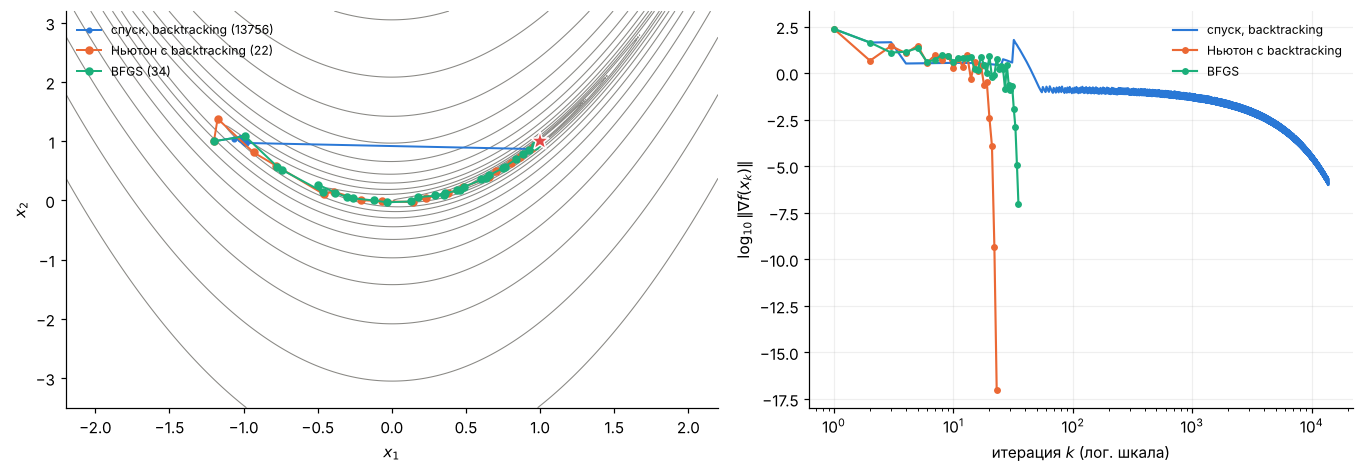

In [12]:
class Counter:                       # обёртка-счётчик вызовов функции
    def __init__(self, f): self.f, self.n = f, 0
    def __call__(self, x): self.n += 1; return self.f(x)


results = {}
for name, run in (("спуск, backtracking", lambda fc: gd(fc, rosen_grad, X0_ROSEN)),
                  ("Ньютон с backtracking", lambda fc: newton_damped(fc, rosen_grad, rosen_hess, X0_ROSEN)),
                  ("BFGS", lambda fc: bfgs(fc, rosen_grad, X0_ROSEN))):
    fc = Counter(rosen)
    x, k, path, gn = run(fc)
    results[name] = (k, fc.n, path, gn)
    print(f"{name:24s}: итераций {k:6d}, вычислений f {fc.n:6d}, x = {x.round(7)}")
k_gd, k_nd, k_b = results["спуск, backtracking"][0], results["Ньютон с backtracking"][0], results["BFGS"][0]
assert abs(k_gd - 13756) <= 700 and abs(k_nd - 22) <= 2 and abs(k_b - 34) <= 2, (k_gd, k_nd, k_b)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.4), gridspec_kw={"width_ratios": [1.2, 1]})
plot_rosen_path([r[2] for r in results.values()], [f"{n} ({r[0]})" for n, r in results.items()], ax=ax1)
plot_grad_norms([r[3] for r in results.values()], list(results), ax=ax2); plt.tight_layout(); plt.show()

**Ответ (б).** Числа совпали с конспектом: спуск $13\,756$ итераций и около $150$ тысяч вычислений $f$ (backtracking каждый раз начинает с $\alpha=1$ и делит его примерно десять раз — вот где прячется цена «бесплатного» спуска), Ньютон с backtracking $22$ итерации и $51$ вычисление, BFGS $34$ итерации и $87$ вычислений (счётчик считает и $f(x_k)$ в начале каждого backtracking; в конспекте $54$ — без них). По графику $\log_{10}\lVert\nabla f\rVert$: у спуска прямая — **линейная** сходимость; у BFGS кривая загибается всё круче — **сверхлинейная**; у Ньютона в конце обрыв, число верных цифр удваивается — **квадратичная** (после нескольких итераций с $\alpha<1$ вдали от минимума).

Цепь: спуск с шагом $1/L$ — $10\,575$ итераций, один шаг Ньютона — точное решение (энергия $13.4417$ в обоих случаях, расхождение $\sim10^{-6}$ — это допуск останова спуска), потому что энергия квадратична и модель Ньютона точна. BFGS с одним backtracking на цепи хрупок: при $N=10$ сходится ($42$ итерации), при $N=20$ не сходится за $10\,000$ — короткие принятые шаги дают пары $(s,y)$, которые портят $H$, направление раздувается, Армихо делит его десятки раз, и метод останавливается на месте при $\lVert\nabla E\rVert\approx4\cdot10^{-6}$. Лечит это правильный линейный поиск (условия Вольфе, лекция 6), точный шаг на квадратичной или масштабирование $H_0$.

In [13]:
energy, grad_E, H_c, b_c, v0 = make_chain(40)
L = np.linalg.eigvalsh(H_c)[-1]
v_gd, k_gd_c, _, _ = gd(energy, grad_E, v0, alpha=1 / L)
v_nt = v0 - np.linalg.solve(H_c, grad_E(v0))
print(f"цепь N=40: спуск с шагом 1/L — {k_gd_c} итераций, E = {energy(v_gd):.4f};  один шаг Ньютона: E = {energy(v_nt):.4f};  |v_gd - v_newton| = {np.linalg.norm(v_gd - v_nt):.1e}")
assert abs(k_gd_c - 10575) <= 530 and abs(energy(v_nt) - 13.4417) < 1e-3
for N in (10, 20):
    e_, g_, H_, b_, v0_ = make_chain(N)
    v_, k_, _, gn_ = bfgs(e_, g_, v0_, maxit=10_000)
    print(f"BFGS с backtracking на цепи N={N}: {'сошёлся за %d итераций' % k_ if k_ < 10_000 else 'НЕ сошёлся за 10000 итераций'}, |grad E| = {gn_[-1]:.1e}")

цепь N=40: спуск с шагом 1/L — 10575 итераций, E = 13.4417;  один шаг Ньютона: E = 13.4417;  |v_gd - v_newton| = 2.4e-06
BFGS с backtracking на цепи N=10: сошёлся за 42 итераций, |grad E| = 1.0e-06


BFGS с backtracking на цепи N=20: НЕ сошёлся за 10000 итераций, |grad E| = 4.1e-06


### (в) Гаусс–Ньютон на синусе из ДЗ 2 (2 балла)

**TODO 4 — шаг Гаусса–Ньютона.** Допишите в `gauss_newton` строку с направлением: $p$ — решение линейного МНК $\min_p\lVert Jp+r\rVert^2$ (`np.linalg.lstsq`). Длина шага — ваш `armijo` на $f=\tfrac12\lVert r\rVert^2$ (демпфированный Гаусс–Ньютон). Проверка под ячейкой: на **линейных** невязках $r=Ax-b$ метод обязан сойтись за одну итерацию к `lstsq`.

Затем:

1. Запустите из $(1,\,3,\,0)$: ожидается $7$ итераций и $f^\ast=1.1393$, $x^\ast\approx(2.10,\,2.997,\,0.700)$. Сравните с вашим `bfgs` на `sine_f` из того же старта (итерации и вызовы функции) и со спуском ($731$ итерация в конспекте).
2. Запустите из всех 20 стартов `starts` ДЗ 2 (`maxit=200`). Сколько стартов пришли к глобальному $f^\ast=1.1393$ (с точностью $10^{-6}$)? Нарисуйте данные и все 20 подогнанных кривых одной картинкой. Объясните в двух предложениях, почему быстрый локальный метод не отменяет мультистарт из ДЗ 2.

Критерии: полный балл — проверка на линейных невязках проходит, числа пункта 1 воспроизведены, картинка и объяснение; половина — метод сходится, но без сравнения или без мультистарта.

In [14]:
def gauss_newton(resid, jac, x0, tol=1e-6, maxit=100):
    """Демпфированный Гаусс–Ньютон для f = 1/2 ||r||^2. Возвращает (x, итераций, путь, нормы градиента)."""
    f = lambda x: 0.5 * np.sum(resid(x) ** 2)
    x = np.asarray(x0, float).copy(); path = [x.copy()]; gnorm = []
    for k in range(maxit):
        r, J = resid(x), jac(x); g = J.T @ r; gnorm.append(np.linalg.norm(g))
        if gnorm[-1] <= tol:
            return x, k, np.array(path), np.array(gnorm)
        p = np.linalg.lstsq(J, -r, rcond=None)[0]           # TODO 4: линеаризуем невязку -> линейный МНК
        x = x + armijo(f, x, p, g) * p; path.append(x.copy())
    return x, maxit, np.array(path), np.array(gnorm)

In [15]:
# проверка TODO 4: линейные невязки r = A x - b — один шаг из любого старта даёт решение lstsq
A_lin = rng.standard_normal((30, 4)); b_lin = rng.standard_normal(30)
x_lin, k_lin, _, _ = gauss_newton(lambda x: A_lin @ x - b_lin, lambda x: A_lin, np.ones(4), tol=1e-10)
assert k_lin == 1 and np.allclose(x_lin, np.linalg.lstsq(A_lin, b_lin, rcond=None)[0]), "на линейных невязках Гаусс–Ньютон должен совпасть с lstsq за одну итерацию: проверьте знак (-r) и что p решает именно min ||J p + r||"
print("TODO 4: ok")

TODO 4: ok


Гаусс–Ньютон: 7 итераций, x* = [2.1014 2.9967 0.7003], f* = 1.1393
BFGS:         12 итераций, 41 вычислений f, f = 1.1393
спуск:        731 итераций, f = 1.1393


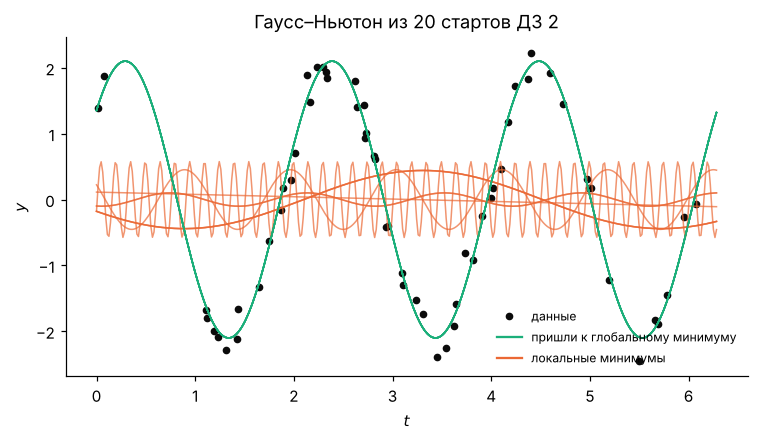

к глобальному минимуму пришли 12 из 20 стартов;  итоговые f: [ 1.14  1.14  1.14  1.14  1.14  1.14  1.14  1.14  1.14  1.14  1.14  1.14 60.14 61.5  61.5  61.5  61.69 64.22 64.25
 64.25]


In [16]:
x_gn, k_gn, path_gn, gn_gn = gauss_newton(sine_resid, sine_jac, X0_SINE)
fc = Counter(sine_f); x_b, k_b, _, _ = bfgs(fc, sine_grad, X0_SINE)
x_g, k_g, _, _ = gd(sine_f, sine_grad, X0_SINE)
print(f"Гаусс–Ньютон: {k_gn} итераций, x* = {x_gn.round(4)}, f* = {sine_f(x_gn):.4f}")
print(f"BFGS:         {k_b} итераций, {fc.n} вычислений f, f = {sine_f(x_b):.4f}")
print(f"спуск:        {k_g} итераций, f = {sine_f(x_g):.4f}")
assert k_gn == 7 and abs(sine_f(x_gn) - 1.1393) < 1e-3

finals = []
tt = np.linspace(0, 2 * np.pi, 400)
plt.figure(figsize=(8, 4)); plt.plot(t_data, y_data, "o", ms=4, color=INK, label="данные")
for s0 in starts:
    xs, ks, _, _ = gauss_newton(sine_resid, sine_jac, s0, maxit=200)
    finals.append(sine_f(xs))
    plt.plot(tt, xs[0] * np.sin(xs[1] * tt + xs[2]), color=AQUA if abs(sine_f(xs) - sine_f(x_gn)) < 1e-6 else ORANGE, lw=1, alpha=0.7)
plt.plot([], [], color=AQUA, label="пришли к глобальному минимуму"); plt.plot([], [], color=ORANGE, label="локальные минимумы")
plt.xlabel("$t$"); plt.ylabel("$y$"); plt.legend(fontsize=8); plt.grid(False); plt.title("Гаусс–Ньютон из 20 стартов ДЗ 2"); plt.show()
n_global = int(np.sum(np.abs(np.array(finals) - sine_f(x_gn)) < 1e-6))
print(f"к глобальному минимуму пришли {n_global} из 20 стартов;  итоговые f: {np.array2string(np.sort(finals), precision=2, max_line_width=120)}")
assert n_global == 12

**Ответ (в).** Из $(1,3,0)$ Гаусс–Ньютон делает $7$ итераций к $f^\ast=1.1393$, $x^\ast=(2.1014,\,2.9967,\,0.7003)$; BFGS из того же старта — около десяти итераций и пары десятков вычислений $f$; спуск — $731$. Из 20 стартов ДЗ 2 к глобальному минимуму пришли $12$, остальные — к локальным минимумам с другой частотой ($f\approx60$–$64$). Задача невыпукла, и никакой локальный метод не выбирает «правильный» бассейн — он лишь быстро доходит до дна того, в который попал; мультистарт по-прежнему нужен, просто каждый старт теперь стоит десяток итераций, а не сотни.

## Бонус (+1 балл). L-BFGS своими руками

Реализуйте L-BFGS с памятью $m=5$: храните последние $m$ пар $(s_i,y_i)$ и вычисляйте $p=-H_kg$ двухпроходной рекурсией (*two-loop recursion*, Nocedal & Wright, алгоритм 7.4) с начальной матрицей $\gamma_kI$, $\gamma_k=s^\top y/y^\top y$ по последней паре; длина шага — ваш `armijo`. Запустите на цепи $N=40$ и сравните с `scipy.optimize.minimize(method="L-BFGS-B", options={"maxcor": 5})` по числу итераций (у SciPy — $75$) и с `np.linalg.solve` по времени; объясните, почему ваш вариант делает больше итераций (подсказка: упражнение 11.9 конспекта). Балл — за работающую рекурсию (проверка: на квадратичной $2\times2$ при $m\ge2$ после двух шагов направление совпадает с ньютоновским) и честное сравнение.

In [17]:
def lbfgs(f, grad, x0, m=5, tol=1e-6, maxit=10_000):
    """L-BFGS: память m пар (s, y), двухпроходная рекурсия, H_0 = gamma I."""
    x = np.asarray(x0, float).copy(); g = grad(x); S, Y = [], []; path = [x.copy()]; gnorm = [np.linalg.norm(g)]
    for k in range(maxit):
        if gnorm[-1] <= tol:
            return x, k, np.array(path), np.array(gnorm)
        q = g.copy(); alphas = []
        for s, y in zip(reversed(S), reversed(Y)):             # первый проход
            a_i = (s @ q) / (y @ s); alphas.append(a_i); q = q - a_i * y
        gamma = (S[-1] @ Y[-1]) / (Y[-1] @ Y[-1]) if S else 1.0
        r = gamma * q
        for (s, y), a_i in zip(zip(S, Y), reversed(alphas)):  # второй проход
            beta = (y @ r) / (y @ s); r = r + s * (a_i - beta)
        p = -r
        s = armijo(f, x, p, g) * p; x_new = x + s; g_new = grad(x_new); y = g_new - g
        if s @ y > 1e-12:
            S.append(s); Y.append(y)
            if len(S) > m: S.pop(0); Y.pop(0)
        x, g = x_new, g_new; path.append(x.copy()); gnorm.append(np.linalg.norm(g))
    return x, maxit, np.array(path), np.array(gnorm)


# проверка: на квадратичной 2x2 после двух пар направление L-BFGS совпадает с ньютоновским -Q^{-1} g
Qb = np.diag([1.0, 50.0]); xb = np.array([50.0, 1.0]); S, Y = [], []
for _ in range(2):
    gq = Qb @ xb; pq = -gq if not S else -np.linalg.inv(Qb) @ gq; aq = -(gq @ pq) / (pq @ Qb @ pq); sq = aq * pq; xb = xb + sq; S.append(sq); Y.append(Qb @ sq)
g_test = np.array([3.0, -2.0]); q = g_test.copy(); alphas = []
for s, y in zip(reversed(S), reversed(Y)):
    a_i = (s @ q) / (y @ s); alphas.append(a_i); q = q - a_i * y
r = (S[-1] @ Y[-1]) / (Y[-1] @ Y[-1]) * q
for (s, y), a_i in zip(zip(S, Y), reversed(alphas)):
    r = r + s * (a_i - (y @ r) / (y @ s))
assert np.allclose(r, np.linalg.inv(Qb) @ g_test), "двухпроходная рекурсия должна давать Q^{-1} g после двух независимых пар"
print("рекурсия: ok")

import time
energy, grad_E, H_c, b_c, v0 = make_chain(40)
t0 = time.perf_counter(); v_l, k_l, _, gn_l = lbfgs(energy, grad_E, v0); t_l = time.perf_counter() - t0
r_sp = minimize(energy, v0, jac=grad_E, method="L-BFGS-B", options={"gtol": 1e-6, "maxiter": 100_000, "maxcor": 5})
t0 = time.perf_counter(); v_s = np.linalg.solve(H_c, -b_c); t_s = time.perf_counter() - t0
print(f"цепь N=40: свой L-BFGS — {k_l} итераций ({t_l:.2f} с), |grad E| = {gn_l[-1]:.1e};  scipy L-BFGS-B — {r_sp.nit} итераций;  solve — {t_s * 1e3:.1f} мс;  |v_lbfgs - v_solve| = {np.linalg.norm(v_l - v_s):.1e}")

рекурсия: ok
цепь N=40: свой L-BFGS — 154 итераций (0.02 с), |grad E| = 8.9e-07;  scipy L-BFGS-B — 75 итераций;  solve — 0.2 мс;  |v_lbfgs - v_solve| = 1.1e-06


**Ответ (бонус).** Двухпроходная рекурсия воспроизводит $Q^{-1}g$ после двух пар на квадратичной $2\times2$. На цепи $N=40$ свой L-BFGS (память 5, Армихо) сходится примерно за $150$ итераций против $75$ у SciPy: линейный поиск по Вольфе умеет принимать $\alpha>1$ там, где кривизна мала, а backtracking — нет, и часть пар $(s,y)$ получается короткими и малоинформативными (упражнение 11.9 конспекта; при $N=100$ наш вариант и вовсе застревает около $\lVert\nabla E\rVert\approx3\cdot10^{-6}$). При этом L-BFGS не хранит матрицу $80\times80$ и не решает систему. `np.linalg.solve` на той же задаче — доли миллисекунды: когда гессиан есть и помещается в память, Ньютон вне конкуренции; L-BFGS — метод для задач, где его нет.